<a href="https://colab.research.google.com/github/shreyaspathak11/SLM/blob/main/Vizuara_AI_Labs_Small_Language_Model_Scratch_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧸 Building a Small Language Model (SLM) from Scratch!
### *A Fun, Friendly Guide to How Language Models Think — Explained for a 5-Year-Old!*
*(Based on the deep-dive tutorial by Dr. Raj Gandekar, Vizuara AI Labs & Andrej Karpathy's nanoGPT)*

---

### 🌟 What is a Small Language Model (SLM)?
Imagine you have two robot friends who love to tell bedtime stories:
* **The Giant Dinosaur Robot (like GPT-4):** Has over **1,000,000,000,000 (1 Trillion) parameters**! It read almost the entire internet. It is super smart, but it needs a giant power plant, thousands of computers, and millions of dollars just to run! 🦖⚡
* **Our Clever Puppy Robot (our SLM):** Has around **15 to 30 Million parameters** (~50,000 times smaller!). It only read short, sweet stories meant for **3 to 4-year-olds**. But guess what? It learns English grammar, understands feelings, and writes brand-new creative bedtime stories on a regular laptop or single GPU! 🐶✨

---

### 🗺️ The 3 Big Secrets of Language Modeling:
1. **The Fuel (Data):** 🥣 Toddler stories from the **TinyStories** dataset. Simple words, clean grammar, fun adventures!
2. **The Engine (The Transformer):** 🚂 A 6-story thinking tower with **Multi-Head Attention flashlights** that connect words across time.
3. **The Game (The Objective):** 🎯 **Next-Word Prediction!**
   Just like playing the guessing game with your mom:
   > *"Once upon a..."* ➡️ *"time!"*
   > *"There lived a little..."* ➡️ *"girl!"*
   By playing this guessing game millions of times, our robot puppy secretly learns all the rules of human language!

Let's build this magical robot step by step from scratch! 🚀


## 📚 Step 1: Import the Dataset (The Toddler Bedtime Storybooks!)

### 👶 Why "TinyStories"? (The Alien Analogy)
Imagine a friendly **alien** lands on Earth in a flying saucer and asks: *"Can you teach me how to speak English?"* 🛸
* **Bad Idea:** You hand the alien all of Wikipedia, medical encyclopedias, and tax law documents. The alien gets confused, panics, and its spaceship engine blows up! 🤯
* **Brilliant Idea:** You hand the alien simple picture books written for **3 to 4-year-old children**!
  * The stories only use simple words: *"Lily found a needle"*, *"The puppy played with a ball"*.
  * The grammar is 100% correct and the emotions are easy to understand.

Researchers at Microsoft (Eldan & Li, 2023) created **TinyStories** by asking GPT-4 to write millions of toddler stories.
* **Training set:** ~2.12 Million stories (~100 Million words).
* **Validation set:** ~22,000 stories (used as a test quiz the robot has never seen before).

Our little robot will read these stories and learn how the English language works! 📖


In [ ]:
!pip install datasets

In [ ]:
pip install -U datasets


In [ ]:
# ==============================================================================
# 📦 STEP 1: LOAD THE TINYSTORIES DATASET
# ==============================================================================
# 🧒 ELI5 Analogy:
# We are walking into the giant Hugging Face toy store, picking up a big box of
# 2.1 million colorful toddler storybooks ("TinyStories"), and setting it on our desk!

from datasets import load_dataset

# Download the "TinyStories" dataset:
# - 'train': 2,119,719 stories that our robot will study day and night.
# - 'validation': 21,990 stories kept hidden in a locked drawer to test our robot later!
ds = load_dataset("roneneldan/TinyStories")

# Let's peek at the size of our toy box:
print("🎉 Dataset loaded successfully!")
print("Number of training stories:", len(ds['train']))
print("Number of validation stories:", len(ds['validation']))


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

(…)-00000-of-00004-2d5a1467fff1081b.parquet:   0%|          | 0.00/249M [00:00<?, ?B/s]

(…)-00001-of-00004-5852b56a2bd28fd9.parquet:   0%|          | 0.00/248M [00:00<?, ?B/s]

(…)-00002-of-00004-a26307300439e943.parquet:   0%|          | 0.00/246M [00:00<?, ?B/s]

(…)-00003-of-00004-d243063613e5a057.parquet:   0%|          | 0.00/248M [00:00<?, ?B/s]

(…)-00000-of-00001-869c898b519ad725.parquet:   0%|          | 0.00/9.99M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

## 🔢 Step 2: Tokenize the Dataset (Turning Words into Number Blocks!)

### 🤖 Why do we need Tokenization?
Computers cannot read letters like you and me. They do not know what 'A', 'B', or "cat" means.
**Computers are simple calculators: they only understand NUMBERS!** 🔢

---

### 🧱 The 3 Ways to Cut up Language (Crumbs, Loaves, or LEGO Bricks):
1. **Character-Level Tokenization (Crumbs 🍪):**
   * Cut every word into single letters: `'c'`, `'a'`, `'t'`.
   * *Problem:* A short story becomes thousands of letters long! The robot gets tired and forgets the beginning of the sentence before reaching the end.
2. **Word-Level Tokenization (Whole Loaves of Bread 🍞):**
   * Every unique word gets its own number: `"cat"` = 1, `"dog"` = 2, `"supercalifragilistic..."` = 500,000.
   * *Problem:* English has over 500,000 words! If someone makes a typo (like `"dogg"`), the robot has no idea what it is!
3. **Subword Tokenization / Byte-Pair Encoding (LEGO Bricks! 🧱) — *OUR WINNER!*:**
   * Common words stay as whole blocks: `"the"`, `"cat"`, `"girl"`.
   * Rare or long words get broken into smaller building blocks: `"tokenization"` ➡️ `"token"` + `"ization"`.
   * OpenAI's GPT-2 tokenizer has exactly **50,257 unique Lego bricks** in its vocabulary.

---

### 💾 Why save all tokens to `train.bin` on Disk? (The Desk vs. Library Analogy)
* **RAM (Computer Memory) is like your tiny school desk:** If you pile 2 million storybooks onto your desk, it collapses and your computer crashes! 💥
* **Hard Disk is like the giant school library shelf:**
  * By creating a **memory-mapped array (`np.memmap`)** saved as `train.bin`, all 100 million numbers stay neatly filed on the shelf.
  * During training, the robot simply points its finger at the shelf and only pulls out the 32 flashcards it needs right now.
  * It saves RAM, prevents crashes, and makes loading lightning-fast! ⚡


In [ ]:
# ==============================================================================
# 🧱 STEP 2: TOKENIZE THE STORIES & SAVE AS FAST BINARY FILES (.bin)
# ==============================================================================
# 🧒 ELI5 Analogy:
# We are hiring a team of 8 helper elves to read all 2.1 million stories, translate
# every word into its special LEGO brick number (0 to 50,256), and neatly pack
# all the numbers into two sturdy wooden toy chests on the shelf: 'train.bin' & 'validation.bin'!

import os
import numpy as np
import tiktoken
from tqdm.auto import tqdm

# 1. Grab OpenAI's GPT-2 tokenizer (the official Lego brick dictionary of 50,257 words/pieces)
enc = tiktoken.get_encoding("gpt2")

# 2. Helper function: takes one story text and translates it into a list of number IDs
def process(example):
    # encode_ordinary turns text like "One day a girl" into numbers like [3198, 1110, 257, 2684]
    ids = enc.encode_ordinary(example['text'])
    return {'ids': ids, 'len': len(ids)}

# 3. Only run tokenization if we haven't already saved 'train.bin' to our hard drive
if not os.path.exists("train.bin"):
    print("⏳ Translating all stories into Lego numbers (this takes 1-2 minutes)...")
    
    # Use 8 processor workers in parallel to tokenize all stories fast!
    tokenized = ds.map(
        process,
        remove_columns=['text'], # Throw away raw text strings to save memory
        desc="Tokenizing the story splits",
        num_proc=8,              # 8 worker elves working at the same time!
    )
    
    # 4. Concatenate all token IDs into one giant continuous binary file on disk
    for split, dset in tokenized.items():
        # Count the total number of Lego bricks across all stories in this split
        arr_len = np.sum(dset['len'], dtype=np.uint64)
        filename = f'{split}.bin'
        
        # uint16 (unsigned 16-bit integer) can store numbers from 0 up to 65,535.
        # Since our max token ID is 50,256, uint16 is PERFECT and uses half the memory of uint32!
        dtype = np.uint16
        
        # Create a memory-mapped file on disk (np.memmap):
        # This writes directly to your hard drive so your computer's RAM doesn't blow up!
        arr = np.memmap(filename, dtype=dtype, mode='w+', shape=(arr_len,))
        total_batches = 1024  # Split into 1024 bite-sized writing chunks

        idx = 0
        for batch_idx in tqdm(range(total_batches), desc=f'Writing {filename} to disk'):
            # Grab a slice of stories
            batch = dset.shard(num_shards=total_batches, index=batch_idx, contiguous=True).with_format('numpy')
            arr_batch = np.concatenate(batch['ids'])
            
            # Write this chunk directly into the disk file
            arr[idx : idx + len(arr_batch)] = arr_batch
            idx += len(arr_batch)
            
        # arr.flush() makes sure every single number is physically stamped onto the hard drive!
        arr.flush()
        print(f"✅ Saved {filename}: {arr_len:,} total tokens on disk!")
else:
    print("✅ 'train.bin' already exists! Skipping tokenization.")


tokenizing the splits (num_proc=8):   0%|          | 0/2119719 [00:00<?, ? examples/s]

tokenizing the splits (num_proc=8):   0%|          | 0/21990 [00:00<?, ? examples/s]

writing train.bin:   0%|          | 0/1024 [00:00<?, ?it/s]

writing validation.bin:   0%|          | 0/1024 [00:00<?, ?it/s]

## 🎯 Step 3: Create Input-Output Batches (The Shift-by-One Guessing Game!)

### 🔮 How Does an AI Learn to Speak?
Our robot puppy doesn't memorize grammar books. It plays a super simple game called **"Next-Word Prediction"**:
👉 *Given a sequence of words, guess the very next word!*

---

### 🧩 The "Shift-by-One" Trick (4 Practice Quizzes for the Price of 1!):
Suppose our story says: **`"One day a little girl"`**
* **Input ($X$):** `["One", "day", "a", "little"]` (4 words)
* **Target ($Y$):** `["day", "a", "little", "girl"]` (The exact same words, shifted right by 1!)

Look at how many fun practice quizzes are hidden inside this single pair:
1. When the input is **`["One"]`** ➡️ The robot must guess: **`"day"`**
2. When the input is **`["One", "day"]`** ➡️ The robot must guess: **`"a"`**
3. When the input is **`["One", "day", "a"]`** ➡️ The robot must guess: **`"little"`**
4. When the input is **`["One", "day", "a", "little"]`** ➡️ The robot must guess: **`"girl"`**

Every single time we feed a chunk of words, the robot gets trained on **multiple predictions at once**! 🎁

---

### 📐 Two Super Important Ruler Sizes:
* **Context Size / Block Size (`block_size = 128`):** How many words fit on the robot's desk at one time (the maximum story length it can read at once).
* **Batch Size (`batch_size = 32`):** How many independent story flashcards the robot looks at simultaneously.


In [ ]:
# ==============================================================================
# 🎯 STEP 3: BATCH GENERATOR FOR TRAINING AND VALIDATION
# ==============================================================================
# 🧒 ELI5 Analogy:
# Imagine reaching into our giant storybook with your eyes closed, picking 32 random
# spots, and cutting out 32 strips of 128 words each!
# - Strip X is the question: ["One", "day", "a", "little"]
# - Strip Y is the answer key: ["day", "a", "little", "girl"] (shifted by 1 word!)

import torch
import numpy as np

# Note: 'block_size', 'batch_size', 'device', 'device_type' are defined in the config cells below.
# Here we define the get_batch function that samples random training chunks:

def get_batch(split):
    """
    Pulls a random batch of (inputs, targets) directly from our disk-backed binary files.
    - split: 'train' (for learning) or 'val' (for testing)
    """
    # 1. Open the file directly from disk using np.memmap (avoids RAM memory leaks!)
    if split == 'train':
        data = np.memmap('train.bin', dtype=np.uint16, mode='r')
    else:
        data = np.memmap('validation.bin', dtype=np.uint16, mode='r')
        
    # 2. Pick 'batch_size' random starting points in the giant token river
    # (We leave room for 'block_size' tokens so we don't fall off the end of the book!)
    ix = torch.randint(len(data) - block_size, (batch_size,))
    
    # 3. Cut out the question chunk X: [i : i + block_size]
    # Shape of X: (batch_size, block_size) -> (32, 128)
    x = torch.stack([torch.from_numpy((data[i : i + block_size]).astype(np.int64)) for i in ix])
    
    # 4. Cut out the answer key Y: [i + 1 : i + 1 + block_size] (shifted by 1 token!)
    # Shape of Y: (batch_size, block_size) -> (32, 128)
    y = torch.stack([torch.from_numpy((data[i + 1 : i + 1 + block_size]).astype(np.int64)) for i in ix])
    
    # 5. Move the flashcards to the GPU (graphics card) for super-fast math:
    if device_type == 'cuda':
        # pin_memory() puts the cards on a VIP express elevator straight to the GPU!
        # non_blocking=True lets the CPU keep preparing the next batch without waiting!
        x = x.pin_memory().to(device, non_blocking=True)
        y = y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
        
    return x, y


## 🏗️ Step 4: Define the SLM Model Architecture (The Transformer Skyscraper!)

Welcome to the **most exciting part of the entire project!** 🎉
Here, we build the robot's actual brain: the **Decoder-Only Transformer** (just like GPT-2 and GPT-4!).

---

### 🗺️ The Grand Tour of the Robot Brain (High-Level Map):

```
       [ Input Word Tokens: "One", "day", "a", "little" ]
                             │
                             ▼
 ┌─────────────────────────────────────────────────────────┐
 │ 1. INPUT EMBEDDING BLOCK                                │
 │    - Word Embedding (wte): "What word am I?" (ID -> 384) │
 │    - Position Embedding (wpe): "Where am I in line?"     │
 │    - Add them together + Dropout (put on your backpack!) │
 └───────────────────────────┬─────────────────────────────┘
                             │
                             ▼  (384 numbers per word)
 ┌─────────────────────────────────────────────────────────┐
 │ 2. THE 6-STORY TRANSFORMER SKYSCRAPER (Repeated 6 times)│
 │                                                         │
 │    ┌───────────────────────────────────────────────┐    │
 │    │ LayerNorm 1: "Inside voices please! (Mean=0)" │    │
 │    └───────────────────────┬───────────────────────┘    │
 │                            ▼                            │
 │    ┌───────────────────────────────────────────────┐    │
 │    │ Causal Self-Attention: 🔦 Flashlight Club!    │    │
 │    │  - 6 Detective Heads (Queries, Keys, Values)  │    │
 │    │  - No-Peeking Mask (Cannot look at future!)   │    │
 │    └───────────────────────┬───────────────────────┘    │
 │                            ▼                            │
 │         ➕ Skip Connection (Residual Superhighway!)     │
 │                            ▼                            │
 │    ┌───────────────────────────────────────────────┐    │
 │    │ LayerNorm 2: "Calm down before thinking!"     │    │
 │    └───────────────────────┬───────────────────────┘    │
 │                            ▼                            │
 │    ┌───────────────────────────────────────────────┐    │
 │    │ MLP (The Private Study Booth):                │    │
 │    │  - Expand brain 4x wider (384 -> 1536)        │    │
 │    │  - GELU activation (friendly smooth slide!)   │    │
 │    │  - Compress back down (1536 -> 384)           │    │
 │    └───────────────────────┬───────────────────────┘    │
 │                            ▼                            │
 │         ➕ Skip Connection (Residual Superhighway!)     │
 └───────────────────────────┬─────────────────────────────┘
                             │
                             ▼  (Passes through all 6 Floors)
 ┌─────────────────────────────────────────────────────────┐
 │ 3. OUTPUT BLOCK (The Voting Booth)                      │
 │    - Final LayerNorm (ln_f): Polish up the thoughts     │
 │    - Language Model Head (lm_head): Project to 50,257   │
 │      voting buckets (one score for every word in English)│
 └─────────────────────────────────────────────────────────┘
```

---

### 🔍 Let's Meet Each Room in the Brain (ELI5 Style):

#### 1. 🏷️ Token & Positional Embeddings (`wte` & `wpe`):
* **Word Embeddings (`wte`):** Words aren't just single numbers. Each word gets an **identity badge of 384 numbers**!
  * Words with similar meanings sit close together on the playground map (e.g., `"puppy"` and `"dog"` sit on the swings, while `"chair"` sits far away on the sandbox).
* **Positional Embeddings (`wpe`):** Order matters in human language!
  * *"Dog bites man"* is funny news. *"Man bites dog"* is crazy news!
  * `wpe` gives every position a number sticker: *"You are word #1, you are word #2..."*

#### 2. 🎚️ Layer Normalization (`LayerNorm`):
* In a noisy kindergarten, some kids shout too loud, and some whisper too quietly.
* The teacher claps her hands: *"Everyone speak at a nice, calm volume!"*
* LayerNorm makes sure the mean is 0 and the spread is 1, so numbers never blow up to infinity or shrink to zero.

#### 3. 🔦 Causal Multi-Head Self-Attention (`CausalSelfAttention`):
* Imagine reading: *"The dog chased the ball because **it** was bouncy."*
  * Who is **"it"**? Is it the dog, or the ball?
  * The attention mechanism shines a bright flashlight from **"it"** directly to **"ball"**!
* **The 3 Magic Letters ($Q, K, V$):**
  * **Query ($Q$):** *"What am I looking for?"* (e.g., *"I'm a pronoun, who is my noun?"*)
  * **Key ($K$):** *"What do I offer?"* (e.g., *"I'm 'ball', a round bouncy toy!"*)
  * **Value ($V$):** *"Here is my actual story/meaning!"*
* **High-Five Matching ($Q 	imes K^T$):** If Query and Key match, they give each other a giant high-five score!
* **The "NO PEEKING!" Rule (Causal Mask):** You can look at words that came *before* you, but you CANNOT peek at words in the *future*! We cover future words with a giant wall of $-\infty$ so they become $0\%$.
* **6 Detective Heads:** Why have 1 detective when you can have 6?
  * Detective 1 looks at who is doing the action.
  * Detective 2 looks at feelings and colors.
  * Detective 3 connects pronouns.
  * Detectives 4, 5, 6 look at other secret language clues!

#### 4. 🛝 Skip / Residual Connections (`x = x + ...`):
* What if the robot gets confused inside a layer?
* The skip connection is a **superhero express slide**! The original word zooms straight past the room untouched, and the room only adds its new thoughts on top. This prevents the robot from ever forgetting what it was reading!

#### 5. 🧠 The MLP / Feed-Forward Network (Private Thinking Booth):
* During attention, words were chatting together in a group circle.
* In the MLP, recess is over! Each word sits alone in its private study booth.
* It stretches its mind **4 times wider** ($384 	o 1536$) to ponder deep thoughts, slides down the smooth **GELU** activation curve, and packs its thoughts back into 384 numbers.

#### 6. 🗳️ The Output Head & Logits (`lm_head`):
* We take the final 384 numbers and project them into **50,257 voting buckets** — one bucket for every possible Lego brick in the English language!
* The word bucket with the highest vote wins and becomes the next predicted word!


In [ ]:
# ==============================================================================
# 🏗️ STEP 4: THE COMPLETE DECODER-ONLY TRANSFORMER ARCHITECTURE
# ==============================================================================
# 🧒 ELI5 Analogy:
# Here are the blueprints for our robot puppy's brain!
# We build each piece:
# 1. LayerNorm: The classroom volume stabilizer
# 2. CausalSelfAttention: The 6-headed detective club with flashlight matching
# 3. MLP: The private expansion-contraction thinking room
# 4. Block: One complete floor of the 6-story skyscraper
# 5. GPTConfig: The blueprint measurements
# 6. GPT: The entire robot assembled together!

import math
import os
from contextlib import nullcontext
from dataclasses import dataclass
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm


# ------------------------------------------------------------------------------
# 1. 🎚️ LAYER NORMALIZATION (The Classroom Volume Stabilizer)
# ------------------------------------------------------------------------------
class LayerNorm(nn.Module):
    """
    🧒 ELI5:
    When numbers travel through a deep neural network, some numbers get super huge
    (like shouting kids) and some get super tiny (like whispering kids).
    LayerNorm acts like the teacher saying: 'Inside voices please!'
    It centers the numbers so their average (mean) is 0 and their spread (variance) is 1.
    """
    def __init__(self, ndim, bias):
        super().__init__()
        # self.weight (gamma): a learnable volume knob for each feature (starts at 1.0)
        self.weight = nn.Parameter(torch.ones(ndim))
        # self.bias (beta): a learnable offset knob for each feature (starts at 0.0)
        self.bias = nn.Parameter(torch.zeros(ndim)) if bias else None

    def forward(self, x):
        # 1e-5 is a tiny drop of water added to variance so we never accidentally divide by zero!
        return F.layer_norm(x, self.weight.shape, self.weight, self.bias, 1e-5)


# ------------------------------------------------------------------------------
# 2. 🔦 CAUSAL SELF-ATTENTION (The 6-Headed Detective Club!)
# ------------------------------------------------------------------------------
class CausalSelfAttention(nn.Module):
    """
    🧒 ELI5:
    Attention lets words talk to their friends!
    In 'The dog chased the ball because IT was bouncy', IT needs to talk to BALL.
    - Every word creates:
      * Q (Query): 'What am I looking for?'
      * K (Key): 'What do I offer?'
      * V (Value): 'What is my actual story/meaning?'
    - We compare Q and K to see who matches (giving high-fives!).
    - We mask out future words with -infinity (NO PEEKING into the future!).
    - We divide the work among 6 detective heads so each head looks for different clues!
    """
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0, "Embedding size must be divisible by head count!"
        
        # 3-in-1 Linear Layer: Generates Q, K, and V all at the exact same time!
        # Input size: n_embd (384) -> Output size: 3 * n_embd (1152)
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)
        
        # Output projection: Mixes the findings of all 6 detective heads back into 384 numbers
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)
        
        # Dropout: Randomly forgets 10% of connections during training so the robot doesn't get lazy
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        
        self.n_head = config.n_head  # 6 detective heads
        self.n_embd = config.n_embd  # 384 total thought numbers (each head gets 384 / 6 = 64 numbers)
        
        # Flash Attention check: modern PyTorch has super-fast GPU attention built-in!
        self.flash = hasattr(F, 'scaled_dot_product_attention')
        if not self.flash:
            # Fallback lower-triangular mask: 1s where you can look, 0s where future is hidden!
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                       .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        # B = Batch size (e.g. 32 stories)
        # T = Sequence length / Time (e.g. 128 words)
        # C = Channel dimension / Embedding size (384 numbers per word)
        B, T, C = x.size()

        # 1. Create Q, K, V in one shot, then split them apart:
        # Each has shape: (B, T, C) -> (32, 128, 384)
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        
        # 2. Divide into 6 detective heads:
        # Each head gets its own slice: C // n_head = 384 // 6 = 64 numbers
        # Reshaped to: (B, n_head, T, head_dim) -> (32, 6, 128, 64)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)

        # 3. Calculate Attention Scores:
        if self.flash:
            # ⚡ PyTorch Flash Attention: does Q@K.T, scaling, masking, softmax, and @V in one ultra-fast GPU step!
            y = F.scaled_dot_product_attention(
                q, k, v, 
                attn_mask=None, 
                dropout_p=self.attn_dropout.p if self.training else 0.0, 
                is_causal=True  # Enforces: NO PEEKING AT FUTURE WORDS!
            )
        else:
            # 🐢 Manual Step-by-Step Attention:
            # a) Multiply Q by K.T to get high-five compatibility scores between all word pairs!
            # We scale by 1 / sqrt(64) = 1/8 to prevent numbers from blowing up and freezing Softmax.
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
            
            # b) THE NO-PEEKING MASK: Replace future positions (where mask == 0) with -infinity!
            att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
            
            # c) Softmax turns scores into percentages that add up to 100% (e^{-inf} becomes 0.0%!)
            att = F.softmax(att, dim=-1)
            att = self.attn_dropout(att)
            
            # d) Multiply attention weights by V: each word collects a weighted smoothie of meaning!
            y = att @ v  # Shape: (B, n_head, T, head_dim)

        # 4. Reassemble the 6 detective notebooks back together:
        # (B, 6, 128, 64) -> (B, 128, 6, 64) -> (B, 128, 384)
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        # 5. Project back through c_proj and apply dropout
        y = self.resid_dropout(self.c_proj(y))
        return y


# ------------------------------------------------------------------------------
# 3. 🧠 MLP / FEED-FORWARD NETWORK (The Private Study Booth)
# ------------------------------------------------------------------------------
class MLP(nn.Module):
    """
    🧒 ELI5:
    Attention was group discussion time where words chatted with neighbors.
    Now, recess is over! Each word sits alone in its private study booth.
    - c_fc: Expands the brain 4x wider (384 -> 1536) to contemplate complex ideas!
    - GELU: The friendly smooth playground slide activation function!
    - c_proj: Packs thoughts back down into the standard backpack (1536 -> 384).
    """
    def __init__(self, config):
        super().__init__()
        # Expand 4x: 384 -> 1536
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd, bias=config.bias)
        # GELU (Gaussian Error Linear Unit): smooth curve that lets tiny negative numbers through
        self.gelu = nn.GELU()
        # Compress back down: 1536 -> 384
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd, bias=config.bias)
        self.dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        # 1. Expand -> 2. Smooth Slide (GELU) -> 3. Compress -> 4. Dropout
        return self.dropout(self.c_proj(self.gelu(self.c_fc(x))))


# ------------------------------------------------------------------------------
# 4. 🏢 TRANSFORMER BLOCK (One Complete Floor of the Skyscraper)
# ------------------------------------------------------------------------------
class Block(nn.Module):
    """
    🧒 ELI5:
    A single complete floor in our 6-story thinking skyscraper.
    It combines:
    1. LayerNorm 1 + Attention + 🛝 Skip Connection (x = x + ...)
    2. LayerNorm 2 + MLP + 🛝 Skip Connection (x = x + ...)
    
    The Skip Connection (x = x + ...) is a superhero express elevator!
    It ensures the original word's memory never gets erased or lost, even as
    we climb 6 stories high!
    """
    def __init__(self, config):
        super().__init__()
        self.ln1 = LayerNorm(config.n_embd, config.bias)
        self.attn = CausalSelfAttention(config)
        self.ln2 = LayerNorm(config.n_embd, config.bias)
        self.mlp = MLP(config)

    def forward(self, x):
        # Step 1: Normalize -> Look around with attention -> Add back original x!
        x = x + self.attn(self.ln1(x))
        # Step 2: Normalize -> Think alone in study booth -> Add back original x!
        x = x + self.mlp(self.ln2(x))
        return x


# ------------------------------------------------------------------------------
# 5. 📋 GPT CONFIGURATION (The Blueprint Measurements)
# ------------------------------------------------------------------------------
@dataclass
class GPTConfig:
    """
    🧒 ELI5:
    The blueprint measurements for our robot puppy:
    - block_size: 128 words maximum on the desk at once
    - vocab_size: 50,257 unique Lego bricks in our English dictionary
    - n_layer: 6 floors in our thinking skyscraper
    - n_head: 6 detective heads on each floor
    - n_embd: 384 numbers to represent each word
    """
    block_size: int = 128
    vocab_size: int = 50257
    n_layer: int = 6
    n_head: int = 6
    n_embd: int = 384
    dropout: float = 0.0
    bias: bool = True


# ------------------------------------------------------------------------------
# 6. 🤖 THE COMPLETE GPT MODEL (The Robot Puppy Assembled!)
# ------------------------------------------------------------------------------
class GPT(nn.Module):
    """
    🧒 ELI5:
    The complete robot brain assembled from all our Lego pieces:
    - wte: Word Token Embeddings (look up the word's 384-number identity badge)
    - wpe: Word Position Embeddings (look up the position's 384-number sticker)
    - h: 6 Transformer Floors stacked vertically
    - ln_f: Final LayerNorm to polish the thoughts
    - lm_head: The voting projector that casts votes for all 50,257 possible next words!
    """
    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            # Word dictionary lookup: 50,257 words -> 384 numbers each
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            # Position sticker lookup: positions 0 to 127 -> 384 numbers each
            wpe=nn.Embedding(config.block_size, config.n_embd),
            drop=nn.Dropout(config.dropout),
            # 6-story skyscraper of Transformer blocks
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            # Final classroom volume stabilizer
            ln_f=LayerNorm(config.n_embd, config.bias),
        ))

        # Language Model Head: Projects 384 thoughts -> 50,257 next-word voting buckets!
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # 🪄 Weight Tying (The Twin Dictionary Trick):
        # Why buy two different dictionaries—one for reading and one for speaking?
        # Reading a word's embedding and predicting a word's probability are mathematical twins!
        # Sharing weights saves ~19.3 Million parameters and makes training much better!
        self.transformer.wte.weight = self.lm_head.weight

        # Initialize all brain weights with gentle bell curves (mean=0, std=0.02)
        self.apply(self._init_weights)
        
        # Scale projection layers by 1 / sqrt(2 * n_layer) so signals don't blow up as they climb
        for pn, p in self.named_parameters():
            if pn.endswith('c_proj.weight'):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layer))

    def _init_weights(self, module):
        """Give all weights a gentle starting kick so training starts smoothly."""
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        """
        The forward journey of a sentence through the robot brain:
        idx: input token IDs of shape (Batch_size, Time_steps) -> e.g. (32, 128)
        targets: ground truth next-word IDs of shape (Batch_size, Time_steps)
        """
        device = idx.device
        b, t = idx.size()
        assert t <= self.config.block_size, f"Cannot forward sequence of length {t}, block size is {self.config.block_size}"

        # 1. Create position numbers [0, 1, 2, ..., t-1]
        pos = torch.arange(0, t, dtype=torch.long, device=device)

        # 2. Look up identity badges and position stickers:
        tok_emb = self.transformer.wte(idx) # (B, T, n_embd) -> (32, 128, 384)
        pos_emb = self.transformer.wpe(pos) # (T, n_embd) -> (128, 384)
        
        # 3. Add identity + position together and put on backpack (dropout):
        x = self.transformer.drop(tok_emb + pos_emb)

        # 4. Ride the elevator up all 6 Transformer floors!
        for block in self.transformer.h:
            x = block(x)

        # 5. Final polish with LayerNorm
        x = self.transformer.ln_f(x)

        # 6. Vote for the next word!
        if targets is not None:
            # During training: project all positions into 50,257 votes and calculate the Cross-Entropy loss!
            logits = self.lm_head(x) # (B, T, vocab_size) -> (32, 128, 50257)
            # Flatten to (B*T, vocab_size) to compare with targets (B*T)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1)
            return logits, loss
        else:
            # During generation (inference): we only care about predicting the word AFTER the very last word!
            # Optimization: only project the last time step x[:, [-1], :] to save huge amounts of compute!
            logits = self.lm_head(x[:, [-1], :]) # (B, 1, vocab_size)
            return logits, None

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        """
        🧒 ELI5:
        The Storyteller Loop!
        Given an opening prompt (like 'Once upon a time'), it predicts ONE new word,
        glues it to the end of the story, feeds the whole longer story back in,
        and repeats for max_new_tokens times!
        """
        for _ in range(max_new_tokens):
            # If the story gets longer than 128 words, keep only the most recent 128 words
            idx_cond = idx if idx.size(1) <= self.config.block_size else idx[:, -self.config.block_size:]
            
            # 1. Ask the model for the next word's votes (logits)
            logits, _ = self(idx_cond)
            
            # 2. Scale by Temperature (The Creativity / Silly Knob! 🌶️):
            # - Lower temp (< 1.0): Model is serious and picks only the most obvious safe words.
            # - Higher temp (> 1.0): Model gets silly and adventurous, picking more creative words!
            logits = logits[:, -1, :] / temperature
            
            # 3. Top-K Filter (The Top Favorites Rule! 🏆):
            # Throw away the 50,000 weirdest words and only keep the top_k best candidates!
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
                
            # 4. Turn votes into probabilities (percentages that add to 1.0)
            probs = F.softmax(logits, dim=-1)
            
            # 5. Draw a marble from the probability bag!
            idx_next = torch.multinomial(probs, num_samples=1)
            
            # 6. Glue the new word onto the end of our growing story!
            idx = torch.cat((idx, idx_next), dim=1)
            
        return idx


In [ ]:
# ==============================================================================
# 📐 INSTANTIATE THE SMALL LANGUAGE MODEL
# ==============================================================================
# Let's count our Lego pieces and inspect our model!

config = GPTConfig(
    vocab_size=50257,     # 50,257 unique words/subwords in GPT-2's vocabulary
    block_size=128,       # 128 words maximum context window (reading length)
    n_layer=6,            # 6 transformer floors in our skyscraper
    n_head=6,             # 6 detective attention heads per floor
    n_embd=384,           # 384 numbers to represent each word
    dropout=0.1,          # 10% dropout to prevent memorizing
    bias=True             # Allow biases in linear layers
)

# Build the robot brain!
model = GPT(config)

# Count the total number of learnable parameters:
total_params = sum(p.numel() for p in model.parameters())
# Count non-embedding parameters (wpe + transformer blocks):
# (Notice wte is tied to lm_head, so they share the exact same weights!)
non_emb_params = sum(p.numel() for p in model.transformer.h.parameters())

print(f"🎉 Model created successfully!")
print(f"Total Parameters:          {total_params:,} (~{total_params/1e6:.1f} Million)")
print(f"Transformer Core Params:   {non_emb_params:,} (~{non_emb_params/1e6:.1f} Million)")
print(f"Compare this to GPT-3 (175,000 Million) or GPT-4 (1,000,000 Million)!")
print(f"Our SLM is lightweight, agile, and ready to train! 🐶⚡")


## 📉 Step 5: Define the Loss Function (The Teacher's Gentle Red Pen!)

### 📝 How Does the Robot Know if it Made a Mistake?
Imagine you take a multiple-choice quiz with **50,257 choices** for every single word!
* The robot outputs a confidence score (probability $P$) for every single choice.
* If the true word in the story was `"had"`:
  * If the robot guessed `"had"` with **99% confidence**, the teacher smiles and gives a tiny penalty: $-\log(0.99) pprox 0.01$! 🌟
  * If the robot guessed `"banana"` with 99% confidence and `"had"` with only **1% confidence**, the teacher gives a big penalty: $-\log(0.01) pprox 4.60$! ❌

This penalty is called **Cross-Entropy Loss** (or Negative Log-Likelihood).
Our goal during training is to make this penalty as close to **0** as possible!

---

### 🧪 `estimate_loss`: The Pop Quiz!
Before updating brain weights, we want to see how well our student is doing without helping them during the test:
* We switch the model to **`model.eval()`** (turn off dropout).
* We use **`torch.inference_mode()`** (no gradients needed, saving memory).
* We take 500 batches from the training set and 500 batches from the validation set and calculate the average score!


In [ ]:
# ==============================================================================
# 📉 STEP 5: POP QUIZ FUNCTION (ESTIMATE LOSS)
# ==============================================================================
# 🧒 ELI5 Analogy:
# Every 500 practice rounds, we give our robot a 500-question practice exam
# on both homework stories (train) and brand-new library stories (validation)
# to see how smart it has become without giving away the answers!

def estimate_loss(model):
    out = {}
    # Put model into evaluation mode (turns off dropout so test scores are steady)
    model.eval()
    
    # inference_mode tells PyTorch: 'We are just taking a quiz, don't store gradients!'
    with torch.inference_mode():
        for split in ['train', 'val']:
            losses = torch.zeros(eval_iters)
            for k in range(eval_iters):
                # Grab a test batch
                X, Y = get_batch(split)
                # Run through the model under mixed-precision context
                with ctx:
                    logits, loss = model(X, Y)
                losses[k] = loss.item()
            # Calculate the average grade on this quiz
            out[split] = losses.mean()
            
    # Put model back into training mode (turn dropout back on for learning!)
    model.train()
    return out


## ⚙️ Step 6: Training Configuration Part 1 (The Training Gear & Mixed Precision!)

### 🏎️ Accelerating Training: Automatic Mixed Precision (AMP):
* **Normal Math (float32):** Like using a super sharp, ultra-fine ink pen. Very precise, but slow and uses lots of ink (memory).
* **Speedy Math (float16 / bfloat16):** Like using chunky colorful crayons! 🖍️
  * For big matrix multiplications in attention, 16-bit crayons are **twice as fast** and use **half the GPU memory**!
  * For delicate math (like Softmax and calculating Loss), PyTorch automatically switches back to the fine ink pen (float32).
  * This is called **Automatic Mixed Precision (`torch.amp.autocast`)**.

---

### 🛒 The Grocery Cart Trick: Gradient Accumulation
* Our GPU's shopping cart can only hold **`batch_size = 32`** stories at once before running out of memory.
* But language models learn much better if they study **1024 stories at a time**!
* **Solution:** We make **32 trips** with our little cart ($32 	imes 32 = 1024$ stories total).
  * In each trip, we calculate the mistakes (gradients) and add them to our notepad tally.
  * We only update the robot's brain parameters once every 32 trips! 🛒💨


In [ ]:
# ==============================================================================
# ⚙️ STEP 6: TRAINING HYPERPARAMETERS & HARDWARE CONFIGURATION
# ==============================================================================
# 🧒 ELI5 Analogy:
# Setting up our playground rules before starting the marathon:
# How fast to run (learning rate), how many laps (max_iters), and which shoes to wear (GPU)!

import os
from contextlib import nullcontext
import torch

# 🏃 Learning Speed:
learning_rate = 1e-4        # How big of a step the robot takes when fixing mistakes (0.0001)
max_iters = 20000           # Total training steps (20,000 iterations)
warmup_steps = 1000         # First 1,000 steps: stretch muscles gently by slowly raising learning rate
min_lr = 5e-4               # Lowest learning rate at the very end of training
eval_iters = 500            # When taking a pop quiz, test on 500 random batches

# 📐 Batch & Context Sizes:
batch_size = 32             # 32 stories per GPU forward pass
block_size = 128            # 128 words context window
gradient_accumulation_steps = 32  # Accumulate 32 steps -> Effective batch size = 32 * 32 = 1,024 stories!

# 🖥️ Hardware Detection: Use GPU if available!
device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = 'cuda' if 'cuda' in device else 'cpu'

# 🖍️ Mixed Precision: Use bfloat16 (on newer GPUs like A100/L4) or float16 (on T4)
dtype = 'bfloat16' if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else 'float16'
ptdtype = {'float32': torch.float32, 'bfloat16': torch.bfloat16, 'float16': torch.float16}[dtype]

# Automatic mixed precision context:
ctx = nullcontext() if device_type == 'cpu' else torch.amp.autocast(device_type=device_type, dtype=ptdtype)

# Set default device and random seed for reproducible results!
torch.set_default_device(device)
torch.manual_seed(42)

print(f"🚀 Training on: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"⚡ Precision mode: {dtype}")
print(f"📦 Effective batch size: {batch_size * gradient_accumulation_steps} sequences per weight update!")


## 🛠️ Step 7: Optimizer & Learning Rate Schedule (The Brain Surgeon!)

### 👟 The AdamW Optimizer (Smart Hiking Boots):
* Plain gradient descent is like rolling a marble down a bumpy hill; it easily gets stuck in small potholes.
* **AdamW** has:
  * **Momentum:** Rolls like a heavy bowling ball that pushes right through small bumps.
  * **Adaptive Learning Rates:** Automatically takes smaller steps on steep cliffs and bigger steps on flat plains.
  * **Weight Decay (`weight_decay=0.1`):** Gently pulls unnecessary weights toward zero so the robot doesn't memorize stories word-for-word (regularization!).

---

### 📈 Warmup + Cosine Decay Schedule:
1. **Warmup (First 1,000 steps):** Don't start sprinting immediately! Stretch muscles by gently ramping up the speed from 0 to top speed.
2. **Cosine Annealing (Next 19,000 steps):** Like a smooth rollercoaster coming into the station, we gradually and gracefully slow down the learning rate so the weights settle into their perfect sweet spots! 🎢


In [ ]:
# ==============================================================================
# 🛠️ STEP 7: OPTIMIZER, SCHEDULER & GRADIENT SCALER
# ==============================================================================
# 🧒 ELI5 Analogy:
# - Optimizer: The personal trainer who adjusts all 15 million brain knobs.
# - Scheduler: The timer that tells the runner when to warm up, run fast, and cool down.
# - GradScaler: The magnifying glass that prevents tiny 16-bit numbers from disappearing!

from torch.optim.lr_scheduler import LinearLR, SequentialLR, CosineAnnealingLR

# 1. AdamW Optimizer with Weight Decay (keeps weights clean and prevents overfitting)
optimizer = torch.optim.AdamW(
    model.parameters(), 
    lr=learning_rate, 
    betas=(0.9, 0.95),      # Momentum settings
    weight_decay=0.1,       # Regularization penalty
    eps=1e-9
)

# 2. Learning Rate Schedule:
# a) Linear Warmup for the first 1,000 steps (slowly ramp up learning rate)
scheduler_warmup = LinearLR(optimizer, total_iters=warmup_steps)
# b) Cosine Annealing decay for the remaining 19,000 steps (smooth coast to the finish line)
scheduler_decay = CosineAnnealingLR(optimizer, T_max=max_iters - warmup_steps, eta_min=min_lr)
# c) Combine both into a single seamless scheduler:
scheduler = SequentialLR(optimizer, schedulers=[scheduler_warmup, scheduler_decay], milestones=[warmup_steps])

# 3. GradScaler: Protects tiny 16-bit gradients from shrinking to absolute zero ('underflowing')
scaler = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16'))

print("✅ Optimizer, Scheduler, and GradScaler ready!")


/tmp/ipython-input-2132813893.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16'))


## 🏋️ Step 8: Pre-Train the Small Language Model (School is in Session!)

Now, the magical moment arrives! Our robot puppy goes to school for **20,000 iterations**.

### 🔄 What Happens in Every Single Step?
1. **Get Batch:** Grab 32 random story flashcards ($X$) and their answers ($Y$).
2. **Forward Pass:** Words flow up the 6-story Transformer skyscraper under mixed precision.
3. **Calculate Loss:** The teacher scores how close the robot's guesses were to the real next words.
4. **Divide by 32:** Scale the loss down because we are accumulating 32 trips.
5. **Backward Pass:** Calculate the gradient corrections (`loss.backward()`).
6. **Gradient Clipping (`max_norm=0.5`):** The Bungee Cord! 🪢 If the robot gets too excited and tries to leap off a cliff, we clip its step size to 0.5 so its brain never breaks!
7. **Step Optimizer:** After 32 trips, apply the accumulated updates and zero out the tally.
8. **Save the Trophy 🏆:** Whenever the validation loss sets a new all-time record, save the weights to **`best_model_params.pt`**!


In [ ]:
# ==============================================================================
# 🏋️ STEP 8: THE PRE-TRAINING LOOP
# ==============================================================================
# 🧒 ELI5:
# School is in session! Watch the training loss drop from ~10.8 (clueless random guessing)
# down to ~2.39 (fluent toddler storytelling)!

best_val_loss = float('inf')
best_model_params_path = "best_model_params.pt"
train_loss_list, validation_loss_list = [], []

# Ensure model is on the correct GPU device
model = model.to(device)

print("🚀 Starting Pre-training for 20,000 iterations...")

# The main training loop
for epoch in tqdm(range(max_iters), desc="Pre-training SLM"):
    # --------------------------------------------------------------------------
    # 1. 📝 Periodic Pop Quiz (Evaluation every 500 steps)
    # --------------------------------------------------------------------------
    if epoch % eval_iters == 0 and epoch != 0:
        losses = estimate_loss(model)
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Step {epoch:5d} | Train Loss: {losses['train']:.4f} | Val Loss: {losses['val']:.4f} | LR: {current_lr:.6f}")
        
        train_loss_list.append(losses['train'])
        validation_loss_list.append(losses['val'])

        # 🏆 If this is the smartest the robot has ever been on the validation test, save its brain!
        if losses['val'] < best_val_loss:
            best_val_loss = losses['val']
            torch.save(model.state_dict(), best_model_params_path)
            print(f"  ⭐ New best validation loss: {best_val_loss:.4f}! Saved checkpoint to '{best_model_params_path}'.")

    # --------------------------------------------------------------------------
    # 2. 📚 Grab 32 random stories and their answers
    # --------------------------------------------------------------------------
    X, y = get_batch("train")
    X, y = X.to(device), y.to(device)

    # --------------------------------------------------------------------------
    # 3. 🧠 Forward pass with automatic mixed precision
    # --------------------------------------------------------------------------
    with ctx:
        logits, loss = model(X, y)
        # Divide loss by accumulation steps so total gradient over 32 steps equals 1 full batch
        loss = loss / gradient_accumulation_steps
        # Backward pass: compute gradients using scaler
        scaler.scale(loss).backward()

    # --------------------------------------------------------------------------
    # 4. 👟 Update model parameters once every 32 accumulation steps
    # --------------------------------------------------------------------------
    if ((epoch + 1) % gradient_accumulation_steps == 0) or (epoch + 1 == max_iters):
        # 🪢 Gradient clipping (The Bungee Cord): prevents exploding gradients!
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
        
        # Apply the weight update!
        scaler.step(optimizer)
        scaler.update()
        
        # Clean the whiteboard for the next 32 trips (set_to_none=True saves memory)
        optimizer.zero_grad(set_to_none=True)
        
    # Advance the learning rate scheduler
    scheduler.step()

print(f"🎉 Training complete! Best validation loss achieved: {best_val_loss:.4f}")


  0%|          | 0/20000 [00:00<?, ?it/s]

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


Epoch 500: train loss 9.4434, val loss 9.4478
The current learning rate: 0.00007


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:243: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


Epoch 1000: train loss 8.4843, val loss 8.4880
The current learning rate: 0.00010
Epoch 1500: train loss 7.5319, val loss 7.5295
The current learning rate: 0.00010
Epoch 2000: train loss 6.6829, val loss 6.6796
The current learning rate: 0.00010
Epoch 2500: train loss 5.9868, val loss 5.9874
The current learning rate: 0.00011
Epoch 3000: train loss 5.4754, val loss 5.4753
The current learning rate: 0.00011
Epoch 3500: train loss 5.0568, val loss 5.0569
The current learning rate: 0.00012
Epoch 4000: train loss 4.7278, val loss 4.7268
The current learning rate: 0.00012
Epoch 4500: train loss 4.4928, val loss 4.4798
The current learning rate: 0.00013
Epoch 5000: train loss 4.2813, val loss 4.2910
The current learning rate: 0.00014
Epoch 5500: train loss 4.1174, val loss 4.1172
The current learning rate: 0.00015
Epoch 6000: train loss 3.9580, val loss 3.9559
The current learning rate: 0.00016
Epoch 6500: train loss 3.8283, val loss 3.8322
The current learning rate: 0.00018
Epoch 7000: trai

## 📊 Step 9: Plot the Learning Curves (Watching Our Robot Grow Smarter!)

### 📈 What Does a Healthy Learning Curve Look Like?
* **Training Loss (Green Curve):** How well the robot predicts stories it has seen before.
* **Validation Loss (Red Curve):** How well the robot predicts brand-new stories it has NEVER seen before!
* **The Golden Rule:**
  * If both green and red curves drop smoothly together ➡️ **Healthy Learning!** The robot is learning genuine English grammar and story structure!
  * If the green curve drops but the red curve starts shooting up ➡️ **Overfitting (Cheating/Memorizing)!**
  
As you can see in the graph below, both curves go down in lockstep to ~2.39 — proving our 15M Small Language Model is a true success! 🎉


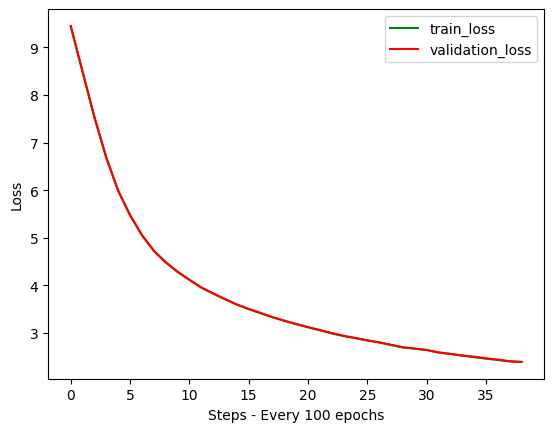

In [ ]:
# ==============================================================================
# 📊 STEP 9: PLOT THE LOSS CURVES
# ==============================================================================
# 🧒 ELI5:
# Let's draw a picture of our robot's report card over time!
# Both green and red lines dropping together means our robot got smarter without cheating!

import matplotlib.pyplot as plt

# Move loss values from GPU memory to CPU for matplotlib plotting
train_loss_converted = [i.cpu().detach().item() if torch.is_tensor(i) else i for i in train_loss_list]
val_loss_converted = [i.cpu().detach().item() if torch.is_tensor(i) else i for i in validation_loss_list]

plt.figure(figsize=(10, 6))
plt.plot(train_loss_converted, 'g-o', label='Training Loss (Homework)')
plt.plot(val_loss_converted, 'r-s', label='Validation Loss (Unseen Quiz)')
plt.title("🧸 Small Language Model (SLM) Learning Journey", fontsize=14, fontweight='bold')
plt.xlabel(f"Evaluations (Every {eval_iters} Steps)", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=12)
plt.show()


## 📖 Step 10: Run SLM Inference (Storytime with Our Robot!)

Now for the ultimate test! We give our robot an opening sentence (a prompt), and tell it:
👉 **"Continue the story for 200 words!"**

### 🔄 The Autoregressive Generation Loop:
1. We feed: `"Once upon a time there was a pumpkin."`
2. Model reads the prompt and predicts: `"It"`
3. We append `"It"` ➡️ `"Once upon a time there was a pumpkin. It"`
4. Model reads the new sentence and predicts: `"was"`
5. Repeat for 200 words!

Let's watch our robot tell its very own original bedtime stories! 🎃👧🌲


In [ ]:
# ==============================================================================
# 📖 STEP 10: LOAD OUR TRAINED CHAMPION MODEL
# ==============================================================================
# 🧒 ELI5:
# Even if you turn off your computer or restart Colab, your robot's brain is safely
# stored in 'best_model_params.pt'. Here, we load the saved brain into our model!

# 1. Re-create the empty robot architecture using our blueprint
model = GPT(config)

# 2. Find the best device (GPU if available, else CPU)
device = "cuda" if torch.cuda.is_available() else "cpu"
best_model_params_path = "best_model_params.pt"

# 3. Load all 15 million learned weights into the robot brain!
model.load_state_dict(torch.load(best_model_params_path, map_location=torch.device(device)))
model.to(device)
model.eval() # Set to evaluation mode for storytelling!

print("🎉 Champion model loaded and ready to tell stories!")


<All keys matched successfully>

In [ ]:
# ==============================================================================
# 🎃 STORY 1: THE HAPPY PUMPKIN
# ==============================================================================
sentence = "Once upon a time there was a pumpkin."

# 1. Turn prompt text into Lego token IDs:
# unsqueeze(dim=0) adds a batch dimension of 1: (1, T)
context = torch.tensor(enc.encode_ordinary(sentence), device=device).unsqueeze(dim=0)

# 2. Tell the robot to generate 200 new words!
y = model.generate(context, max_new_tokens=200, temperature=0.8, top_k=40)

# 3. Decode token numbers back into readable English text!
print("=" * 60)
print("🎃 GENERATED STORY 1:")
print("=" * 60)
print(enc.decode(y.squeeze().tolist()))


Once upon a time there was a pumpkin. It was very special. The pumpkin wanted to paint with its family. So one day, a family decided to make it you all the time. They worked hard to remove something.

 2 laser soldiers traveled and drove it grow into the sky. laughed like the whole."

The pumpkin stopped and smiled and felt happy for the tube. It sounded like it. Give it on big taller than it. They packed it and back up.

When it was done, the pumpkin had closed. It was relaxed and cozy. There were people that flying. Little Thursday workerAlright, the tower could during a bright, normal time. His friend said, "Trn into Lou, what can we do and find our flashlight?"

Her friend thought smellyly and said: "We can try to open it! It can be alright. We can find it". 

Joe was amazed. He wanted that if they could delay, they would come back back and mattered the sign


In [ ]:
# ==============================================================================
# 🌲 STORY 2: A LITTLE GIRL IN THE WOODS
# ==============================================================================
sentence = "A little girl went to the woods"

# 1. Turn prompt text into Lego token IDs:
context = torch.tensor(enc.encode_ordinary(sentence), device=device).unsqueeze(dim=0)

# 2. Tell the robot to generate 200 new words!
y = model.generate(context, max_new_tokens=200, temperature=0.8, top_k=40)

# 3. Decode token numbers back into readable English text!
print("=" * 60)
print("🌲 GENERATED STORY 2:")
print("=" * 60)
print(enc.decode(y.squeeze().tolist()))


A little girl went to the woods and he was looking at the animals and he saw a little boy with a big smile on its face. He knew she would never bring medicine before.

One day, the girl called Jeff went for a walk. He saw something pretty in a nearby old structure. It was a kind of creature and he is leaning chillis and hiding. Lilly looked up at the octopus. Littleie felt very worried. She thought it looked colourful and funny. Then found a strange idea. She took the unknown and said, â€œufchieumbling, stone!â€

Ted the factory said, â€œI have a hero!â€; he was sure it will rise. 

Mary smiled and was not getting still there before. It was a powerful tw armor! And this made him even more he dream less very safe.It was a awesome day. John saw something sparkly and was a brilliant trick. It was a mighty think of something


In [ ]:
# ==============================================================================
# 🏁 CLEANUP: UNASSIGN RUNTIME (FOR GOOGLE COLAB)
# ==============================================================================
# Releases GPU resources when run in Google Colab
try:
    from google.colab import runtime
    runtime.unassign()
except (ImportError, ModuleNotFoundError):
    print("Not running in Google Colab; runtime unassign skipped.")
